# Subsetting: the malignant compartment

From shiao.h5ad (619,693 x 30,869, phase 01) to a raw, re-filtered object holding only the
cells 03_1 found aneuploid.

- join the 03_1 call (cnv_status.csv) and re-annotation (cell_annotation.csv)
- subset on the measurement, not on a label: cnv_status == 'malignant'
- record the criterion in compartment == 'tum', keep the pre-CNV label as cell_type_01_4
- recompute fraction from the post-CNV cell_type (it is a function of that column)
- restore .X = raw counts and drop every slot phase 01 computed on the full object
  (PCA, UMAP, neighbours, HVG flags, scran size factors, leiden columns, stale palettes)
- drop the categories left empty by the subset
- recompute the QC metrics, re-apply the cell thresholds, re-run the gene filter
- drop the cohorts left under 100 cells
- write shiao_tum_raw.h5ad, the input of subsetting_all.sh

Nothing is normalized here: scran runs in the next step, on this file, because its size factors
have to be estimated on the cells that remain.

The subset is taken on the CNV call and not on an epithelial label: the CellTypist labels cannot
tell normal from malignant epithelium, so an epithelial subset would mix the two and its HVGs, PCA
and DRVI dimensions would describe that mixture.

## Packages and paths

In [104]:
# Core scverse libraries
from __future__ import annotations

# Main
import anndata as ad
import scanpy as sc
import pandas as pd
import numpy as np
import scipy.sparse as sp
import os
import sys

# Plotting
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib import colors
import seaborn as sns

# Scanpy setting: clean white background and high resolution figures
sc.set_figure_params(dpi=300, facecolor='white')
# Set the level of verbosity of scanpy to get more detailed info
sc.settings.verbosity = 3

import importlib
# cell_set lives in the phase's utils/.
sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), 'utils'))
import cell_set as C
importlib.reload(C)

PHASE_DIR = os.path.dirname(os.getcwd())  # 03_drvi_tumoral_epi/
REPO_ROOT = os.path.dirname(PHASE_DIR)

FIG_DIR = os.environ.get('FIG_DIR', os.path.join(PHASE_DIR, 'figures', '03_2_subset_and_qc'))
os.makedirs(FIG_DIR, exist_ok=True)
sc.settings.figdir = FIG_DIR

# Colour of every panel below (matplotlib's tab:green).
QC_COLOR = '#2CA02C'
SET_TITLE = 'malignant'

# Tell Jupyter to show all outputs and not only the last one
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'

print('cwd      :', os.getcwd())
print('REPO_ROOT:', REPO_ROOT)
print('FIG_DIR  :', FIG_DIR)
print('colour   :', QC_COLOR)

<module 'cell_set' from '/home/catt/QCB-thesis-final/03_drvi_tumoral_epi/utils/cell_set.py'>

cwd      : /home/catt/QCB-thesis-final/03_drvi_tumoral_epi/03_2_subsetting
REPO_ROOT: /home/catt/QCB-thesis-final
FIG_DIR  : /home/catt/QCB-thesis-final/03_drvi_tumoral_epi/figures/03_2_subset_and_qc
colour   : #2CA02C


Setup the directory of the data. This is the path to the cluster data folder (outside the repo) or
to the local data folder, like in this case. Raw and heavy intermediate objects live here; the repo
holds only code and lightweight QC figures.

Everything this phase produces goes in 03_tum/, next to what 03_1 already wrote there.

In [105]:
DATA_DIR = os.environ['DATA_DIR'] # export DATA_DIR=<data root> before starting Jupyter
DATA_DIR = os.path.abspath(os.path.expanduser(DATA_DIR))
os.environ['DATA_DIR'] = DATA_DIR  # absolute from now on: re-running this cell is a no-op

INPUT_H5AD = os.path.join(DATA_DIR, 'shiao.h5ad')
STATUS_CSV = str(C.status_csv())
ANNOT_CSV = str(C.annot_csv())
OUTPUT_H5AD = str(C.path('_raw.h5ad'))

for path, produced_by in ((INPUT_H5AD, 'phase 01'),
                          (STATUS_CSV, '03_1/call_malignant.ipynb'),
                          (ANNOT_CSV, '03_1/recelltypist_nonmalignant.py')):
    if not os.path.exists(path):
        raise FileNotFoundError(f'missing {path}\n(produced by {produced_by}; run it first)')

C.banner('03_2 subset and QC')
print('Input :', INPUT_H5AD, f'({os.path.getsize(INPUT_H5AD) / 1024 ** 3:.2f} GB)')


03_2 subset and QC  |  run drvi_tum_64_nomt
DATA_DIR : /home/catt/QCB-thesis-final/datasets

Input : /home/catt/QCB-thesis-final/datasets/shiao.h5ad (4.41 GB)


## Parameters

The cell thresholds are the same as 01_2. This is the place to make the malignant
compartment stricter. They all live in [cell_set.py](../utils/cell_set.py), with the argument for each
next to it, because four scripts downstream read the same numbers.

| | value |
|---|---|
| MIN_GENES | 100 |
| MAX_PCT_MT | 10 |
| MIN_CELLS (gene filter) | 3 |
| MIN_CELLS_PER_COHORT | 100 |
| DROP_INCOMPLETE_COHORTS | False |

### What is *not* re-run, and why

Scrublet and fraction_reassignment are not rerun.
Cell cycle scoring, scran, HVGs, PCA. Re-run, but by subsetting_all.sh, not here.

In [106]:
print('cell filter : n_genes_by_counts >', C.MIN_GENES, '| pct_counts_mt <', C.MAX_PCT_MT)
print('gene filter : detected in >=', C.MIN_CELLS, 'cells')
print('cohort size : >=', C.MIN_CELLS_PER_COHORT, 'cells')
print('cohort completeness filter:', 'ON' if C.DROP_INCOMPLETE_COHORTS else 'OFF')
print()
print('keys:', C.BATCH_KEY, '|', C.LABEL_KEY, '(post-CNV) |', C.PRIOR_LABEL_KEY, '(pre-CNV) |',
      C.STATUS_KEY)

cell filter : n_genes_by_counts > 100 | pct_counts_mt < 10
gene filter : detected in >= 3 cells
cohort size : >= 100 cells
cohort completeness filter: OFF

keys: cohort | cell_type (post-CNV) | cell_type_01_4 (pre-CNV) | cnv_status


## Load the full object

In [107]:
# Only .obs / .var / .uns here, no need to load the full .X matrix yet, which is large and slow to read.
import h5py
from anndata.io import read_elem, sparse_dataset

h5 = h5py.File(INPUT_H5AD, 'r')
adata = ad.AnnData(obs=read_elem(h5['obs']), var=read_elem(h5['var']), uns=read_elem(h5['uns']))
adata

AnnData object with n_obs × n_vars = 619693 × 30869
    obs: 'sample', 'batch', 'cohort', 'treatment', 'fraction', 'dataset_origin', 'response', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'is_doublet_shiao', 'high_umi_doublet', 'size_factors', 'S_score', 'G2M_score', 'phase', 'cell_type', 'celltypist_predicted', 'optscib_unintegrated_leiden_0.1', 'optscib_unintegrated_leiden_0.2', 'optscib_unintegrated_leiden_0.3', 'optscib_unintegrated_leiden_0.4', 'optscib_unintegrated_leiden_0.5', 'optscib_unintegrated_leiden_0.6', 'optscib_unintegrated_leiden_0.7', 'optscib_unintegrated_leiden_0.8', 'optscib_unintegrated_leiden_0.9', 'optscib_unintegrated_leiden_1.0', 'optscib_unintegrated_leiden'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts',

## The 03_1 call, joined on

Two tables, both keyed by the cell ids of shiao.h5ad and both covering all 619,693 of them:

- cnv_status.csv - cnv_status (malignant / non_malignant / not_tested) and the two
  continuous axes the call was made on, cnv_score and cnv_corr;
- cell_annotation.csv - cell_type_cnv, the CellTypist re-annotation of the non-malignant
  cells, with malignant as the single label for the rest.

The join is asserted total in both directions: a cell missing from either table would otherwise be
silently dropped or silently treated as untested.

In [108]:
status = pd.read_csv(STATUS_CSV, index_col=0)
annot = pd.read_csv(ANNOT_CSV, index_col=0)

for name, tbl in ((os.path.basename(STATUS_CSV), status),
                  (os.path.basename(ANNOT_CSV), annot)):
    missing = adata.obs_names.difference(tbl.index)
    extra = tbl.index.difference(adata.obs_names)
    assert len(missing) == 0, f'{len(missing):,} cells of shiao.h5ad have no row in {name}'
    assert len(extra) == 0, f'{name} has {len(extra):,} rows not in shiao.h5ad'
    print(f'{name}: {len(tbl):,} rows, joins 1:1')

adata.obs[C.STATUS_KEY] = status.loc[adata.obs_names, C.STATUS_KEY].to_numpy()
for col in ('cnv_score', 'cnv_corr'):
    adata.obs[col] = status.loc[adata.obs_names, col].to_numpy()

# The pre-CNV label is stored under its own name BEFORE `cell_type` is overwritten. It is the
# only non-constant label the malignant subset has.
adata.obs[C.PRIOR_LABEL_KEY] = adata.obs[C.LABEL_KEY].astype(str)
adata.obs[C.LABEL_KEY] = annot.loc[adata.obs_names, 'cell_type_cnv'].astype(str)
adata.obs['celltypist_predicted_cnv'] = annot.loc[adata.obs_names, 'celltypist_predicted_cnv'].astype(str)

print()


cnv_status.csv: 619,693 rows, joins 1:1
cell_annotation.csv: 619,693 rows, joins 1:1



## Subset

Only the aneuploid cells are kept (cnv_status equal to malignant).

In [109]:
n_before = adata.n_obs
keep = (adata.obs[C.STATUS_KEY] == 'malignant').to_numpy()
print(f'keeping {keep.sum():,} of {n_before:,} cells ({keep.sum() / n_before:.1%})')

rows = np.flatnonzero(keep)
counts = sparse_dataset(h5['layers']['counts'])[rows]
h5.close()
sub = ad.AnnData(X=counts.copy(), obs=adata.obs.iloc[rows].copy(), var=adata.var.copy(),
                 uns=adata.uns, layers={'counts': counts})
del adata
sub.obs[C.COMPARTMENT_KEY] = pd.Categorical([C.compartment()] * sub.n_obs)
sub

keeping 42,291 of 619,693 cells (6.8%)


AnnData object with n_obs × n_vars = 42291 × 30869
    obs: 'sample', 'batch', 'cohort', 'treatment', 'fraction', 'dataset_origin', 'response', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'is_doublet_shiao', 'high_umi_doublet', 'size_factors', 'S_score', 'G2M_score', 'phase', 'cell_type', 'celltypist_predicted', 'optscib_unintegrated_leiden_0.1', 'optscib_unintegrated_leiden_0.2', 'optscib_unintegrated_leiden_0.3', 'optscib_unintegrated_leiden_0.4', 'optscib_unintegrated_leiden_0.5', 'optscib_unintegrated_leiden_0.6', 'optscib_unintegrated_leiden_0.7', 'optscib_unintegrated_leiden_0.8', 'optscib_unintegrated_leiden_0.9', 'optscib_unintegrated_leiden_1.0', 'optscib_unintegrated_leiden', 'cnv_status', 'cnv_score', 'cnv_corr', 'cell_type_01_4', 'celltypist_predicted_cnv', 'compartment

In [110]:
# The composition this phase will work with, before any further filtering.
print('Cells per pre-CNV CellTypist label (cell_type_01_4):')
print(sub.obs[C.PRIOR_LABEL_KEY].value_counts().loc[lambda s: s > 0].to_string())
print()
print('Cells per post-CNV label (cell_type):')
print(sub.obs[C.LABEL_KEY].value_counts().loc[lambda s: s > 0].to_string())
print()
print('Cells per cohort x treatment:')
pd.crosstab(sub.obs[C.BATCH_KEY], sub.obs[C.TREATMENT_KEY])

Cells per pre-CNV CellTypist label (cell_type_01_4):
cell_type_01_4
Lumsec-prol      22392
Lumsec-basal     13393
LummHR-SCGB       4621
Lumsec-KIT        1198
LummHR-major       437
basal              110
Lumsec-major       103
LummHR-active       29
Lumsec-myo           6
Lumsec-HLA           2

Cells per post-CNV label (cell_type):
cell_type
malignant    42291

Cells per cohort x treatment:


treatment,BASE,PD1,RTPD1
cohort,,,
Patient01,253,0,116
Patient03,85,4,0
Patient05,62,32,0
Patient09,279,149,43
Patient10,63,136,0
Patient11,729,385,2
Patient16,583,7098,3
Patient17,170,218,1998
Patient18,164,570,12


## Restore the raw counts and drop the phase-01 global slots

.X in shiao.h5ad is the scran log-normalized matrix of the full object
.layers['counts'] is the original unprocessed matrix, so it becomes .X again and scran_norm_tum.py
re-normalizes from there.

The same argument applies to everything else phase 01 derived: the PCA, the neighbour graph and the UMAP
on that PCA.

In [111]:
# Raw counts back in .X (kept in .layers['counts'] as well, untouched)
counts = sub.layers['counts']
sub.X = counts.copy()
if sp.issparse(sub.X) and not sp.isspmatrix_csr(sub.X):
    sub.X = sub.X.tocsr()

x_values = sub.X.data if sp.issparse(sub.X) else np.asarray(sub.X).ravel()
print('dtype:', sub.X.dtype, '| integer values:', bool(np.allclose(x_values, np.round(x_values))))
print('min:', x_values.min(), '| max:', x_values.max())

dtype: float32 | integer values: True
min: 1.0 | max: 11105.0


In [112]:
# Drop the derived matrices and graphs
print('obsm:', list(sub.obsm), '| varm:', list(sub.varm), '| obsp:', list(sub.obsp))
del sub.obsm, sub.obsp, sub.varm

dropped_uns = []
for key in list(sub.uns):
    if key.startswith(('pca', 'neighbors', 'umap', 'optscib_')) or key == 'log1p':
        del sub.uns[key]; dropped_uns.append(key)
# Stale palettes: `cell_type` has a different vocabulary now.
for key in ('cell_type_colors', 'dataset_origin_colors'):
    if sub.uns.pop(key, None) is not None:
        dropped_uns.append(key)
print('uns dropped:', dropped_uns)
print('uns left   :', list(sub.uns))

obsm: [] | varm: [] | obsp: []
uns dropped: ['log1p', 'neighbors', 'optscib_unintegrated_leiden_0.1', 'optscib_unintegrated_leiden_0.2', 'optscib_unintegrated_leiden_0.3', 'optscib_unintegrated_leiden_0.4', 'optscib_unintegrated_leiden_0.5', 'optscib_unintegrated_leiden_0.6', 'optscib_unintegrated_leiden_0.7', 'optscib_unintegrated_leiden_0.8', 'optscib_unintegrated_leiden_0.9', 'optscib_unintegrated_leiden_1.0', 'pca', 'umap', 'cell_type_colors', 'dataset_origin_colors']
uns left   : []


In [113]:
# Drop the derived .obs columns: scran size factors, the leiden sweep of 01_5, and the cell cycle
# scores (re-scored in the next step against expression bins built on THIS population).
DROP_OBS = ['size_factors', 'S_score', 'G2M_score', 'phase']
DROP_OBS += [c for c in sub.obs.columns if c.startswith('optscib_unintegrated_leiden')]
present = [c for c in DROP_OBS if c in sub.obs]
sub.obs.drop(columns=present, inplace=True)
print('obs dropped:', present)

# .var: the per-gene stats and the HVG flag were computed over the full object.
DROP_VAR = ['highly_variable', 'n_cells', 'n_cells_by_counts', 'mean_counts',
            'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts']
present_var = [c for c in DROP_VAR if c in sub.var]
sub.var.drop(columns=present_var, inplace=True)
print('var dropped:', present_var)
print()
print('obs left:', list(sub.obs.columns))

obs dropped: ['size_factors', 'S_score', 'G2M_score', 'phase', 'optscib_unintegrated_leiden_0.1', 'optscib_unintegrated_leiden_0.2', 'optscib_unintegrated_leiden_0.3', 'optscib_unintegrated_leiden_0.4', 'optscib_unintegrated_leiden_0.5', 'optscib_unintegrated_leiden_0.6', 'optscib_unintegrated_leiden_0.7', 'optscib_unintegrated_leiden_0.8', 'optscib_unintegrated_leiden_0.9', 'optscib_unintegrated_leiden_1.0', 'optscib_unintegrated_leiden']
var dropped: ['highly_variable', 'n_cells', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts']

obs left: ['sample', 'batch', 'cohort', 'treatment', 'fraction', 'dataset_origin', 'response', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'is_doublet_shiao', 'high_umi_doublet', 'cel

In [114]:
old_fraction = sub.obs['fraction'].astype(str).copy()
sub.obs['fraction'] = C.reassign_fraction(sub.obs[C.LABEL_KEY].astype(str))
moved = (old_fraction != sub.obs['fraction'].astype(str))
print(f'fraction recomputed: {moved.sum():,} of {sub.n_obs:,} cells changed')
if moved.any():
    print(pd.crosstab(old_fraction[moved], sub.obs['fraction'].astype(str)[moved]).to_string())
print()
print(sub.obs['fraction'].value_counts().to_string())

fraction recomputed: 0 of 42,291 cells changed

fraction
non_imm    42291
imm            0


### Categories left empty by the subset

cell_type was a categorical with 48 observed labels in the full object; after the subset only a
few carry cells. Empty categories are not cosmetic: they end up in every groupby and in the legend
of every figure.

In [115]:
for col in sub.obs.columns:
    if isinstance(sub.obs[col].dtype, pd.CategoricalDtype):
        before = len(sub.obs[col].cat.categories)
        sub.obs[col] = sub.obs[col].cat.remove_unused_categories()
        after = len(sub.obs[col].cat.categories)
        if before != after:
            print(f'{col}: {before} -> {after} categories')

print()
print('Observed post-CNV labels :', sub.obs[C.LABEL_KEY].nunique())
print('Observed pre-CNV labels  :', sub.obs[C.PRIOR_LABEL_KEY].nunique())
print('Observed batches         :', sub.obs[C.BATCH_KEY].nunique())
print('compartment:', sub.obs[C.COMPARTMENT_KEY].cat.categories.tolist(),
      '| fraction:', sub.obs['fraction'].cat.categories.tolist())

sample: 148 -> 91 categories
batch: 148 -> 91 categories
cohort: 34 -> 24 categories
fraction: 2 -> 1 categories
celltypist_predicted: 58 -> 57 categories

Observed post-CNV labels : 1
Observed pre-CNV labels  : 10
Observed batches         : 24
compartment: ['tum'] | fraction: ['non_imm']


## Quality control metrics, recomputed

The QC columns inherited from 01_2 describe the full gene set of the full object. total_counts
and n_genes_by_counts are per-cell sums, so removing *cells* leaves them unchanged - but they
will change as soon as genes are dropped below, and the mitochondrial and ribosomal flags have to
be rebuilt on the current .var anyway.

In [116]:
sub.var['mt'] = np.asarray(sub.var_names.str.startswith('MT-'), dtype=bool)
sub.var['ribo'] = np.asarray(sub.var_names.str.startswith(('RPS', 'RPL')), dtype=bool)
print('mitochondrial genes:', int(sub.var['mt'].sum()), '| ribosomal:', int(sub.var['ribo'].sum()))

sc.pp.calculate_qc_metrics(sub, qc_vars=['mt', 'ribo'], percent_top=None, log1p=True, inplace=True)
sub.obs[['n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'pct_counts_ribo']].describe().round(2)

mitochondrial genes: 13 | ribosomal: 102


,n_genes_by_counts,total_counts,pct_counts_mt,pct_counts_ribo
count,42291.00,42291.00,42291.00,42291.00
mean,1806.94,6321.30,3.73,17.59
std,1357.09,7630.43,2.86,8.28
min,142.00,195.00,0.00,0.42
25%,679.00,1185.00,1.13,12.19
50%,1407.00,3338.00,3.35,16.17
75%,2597.00,8542.50,5.91,21.28
max,7886.00,65338.00,10.00,71.20


### QC figures (before the cell filter)

One panel per round: the top row is the clean violin, the bottom row the same violin with every
cell drawn on top of it.

wrote violin_tum_qc_before_filter_unintegrated_comparison.png


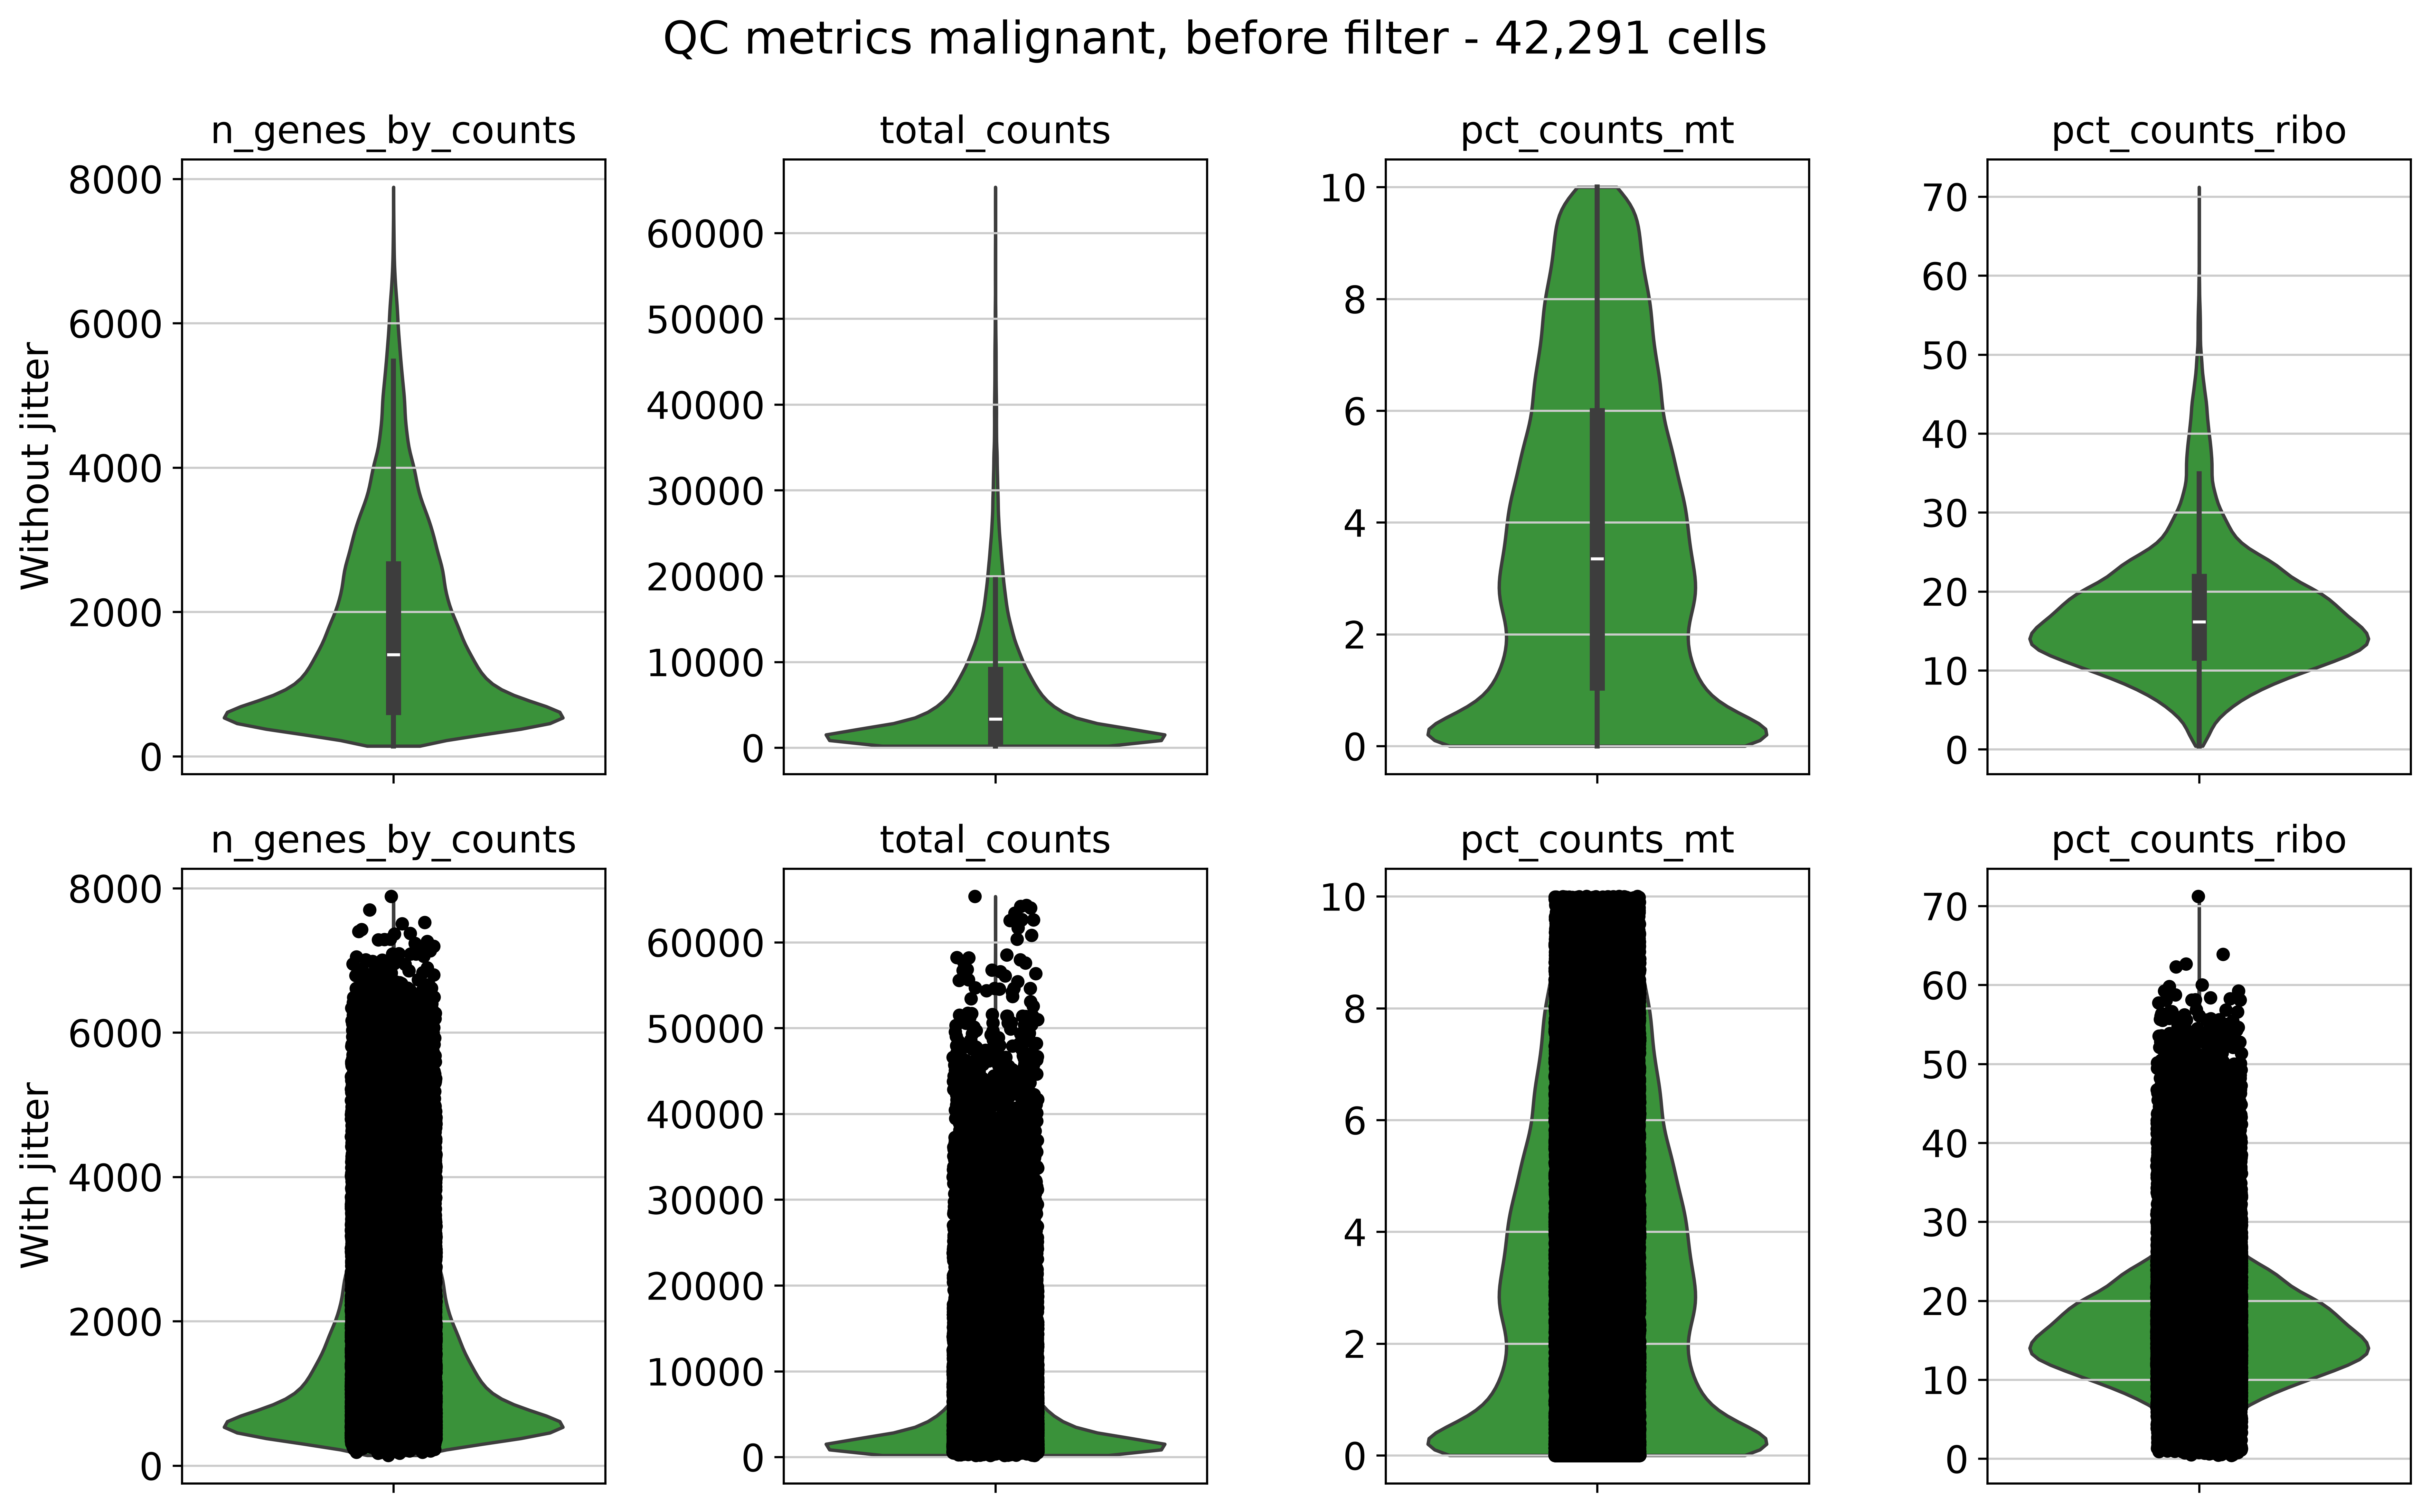

In [117]:
QC_METRICS = ['n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'pct_counts_ribo']

def violin_qc(obs, stage, suffix=None, metrics=QC_METRICS):
    """The 2 x 4 QC panel: top row without jitter, bottom row with it."""
    suffix = suffix or C.compartment()
    fig, axes = plt.subplots(2, len(metrics), figsize=(3.2 * len(metrics), 8))

    for col, metric in enumerate(metrics):
        # Normal violin
        sns.violinplot(data=obs, y=metric, ax=axes[0, col], color=QC_COLOR, cut=0)

        # Violin + default jitter
        sns.violinplot(data=obs, y=metric, ax=axes[1, col], color=QC_COLOR, cut=0)
        sns.stripplot(data=obs, y=metric, ax=axes[1, col], jitter=True, color='black')

        # Formatting
        axes[0, col].set_title(metric)
        axes[1, col].set_title(metric)
        for row in range(2):
            axes[row, col].set_xlabel('')
            axes[row, col].set_ylabel('')

    # Row labels
    axes[0, 0].set_ylabel('Without jitter')
    axes[1, 0].set_ylabel('With jitter')

    fig.suptitle(f"QC metrics {SET_TITLE}, {stage.replace('_', ' ')} "
                 f"- {len(obs):,} cells")
    fig.tight_layout()

    name = f'violin_{suffix}_qc_{stage}_unintegrated_comparison.png'
    fig.savefig(os.path.join(FIG_DIR, name), dpi=300, bbox_inches='tight')
    print('wrote', name)
    plt.show()


violin_qc(sub.obs, 'before_filter')

/tmp/ipykernel_37641/2099286763.py:2: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.scatter(


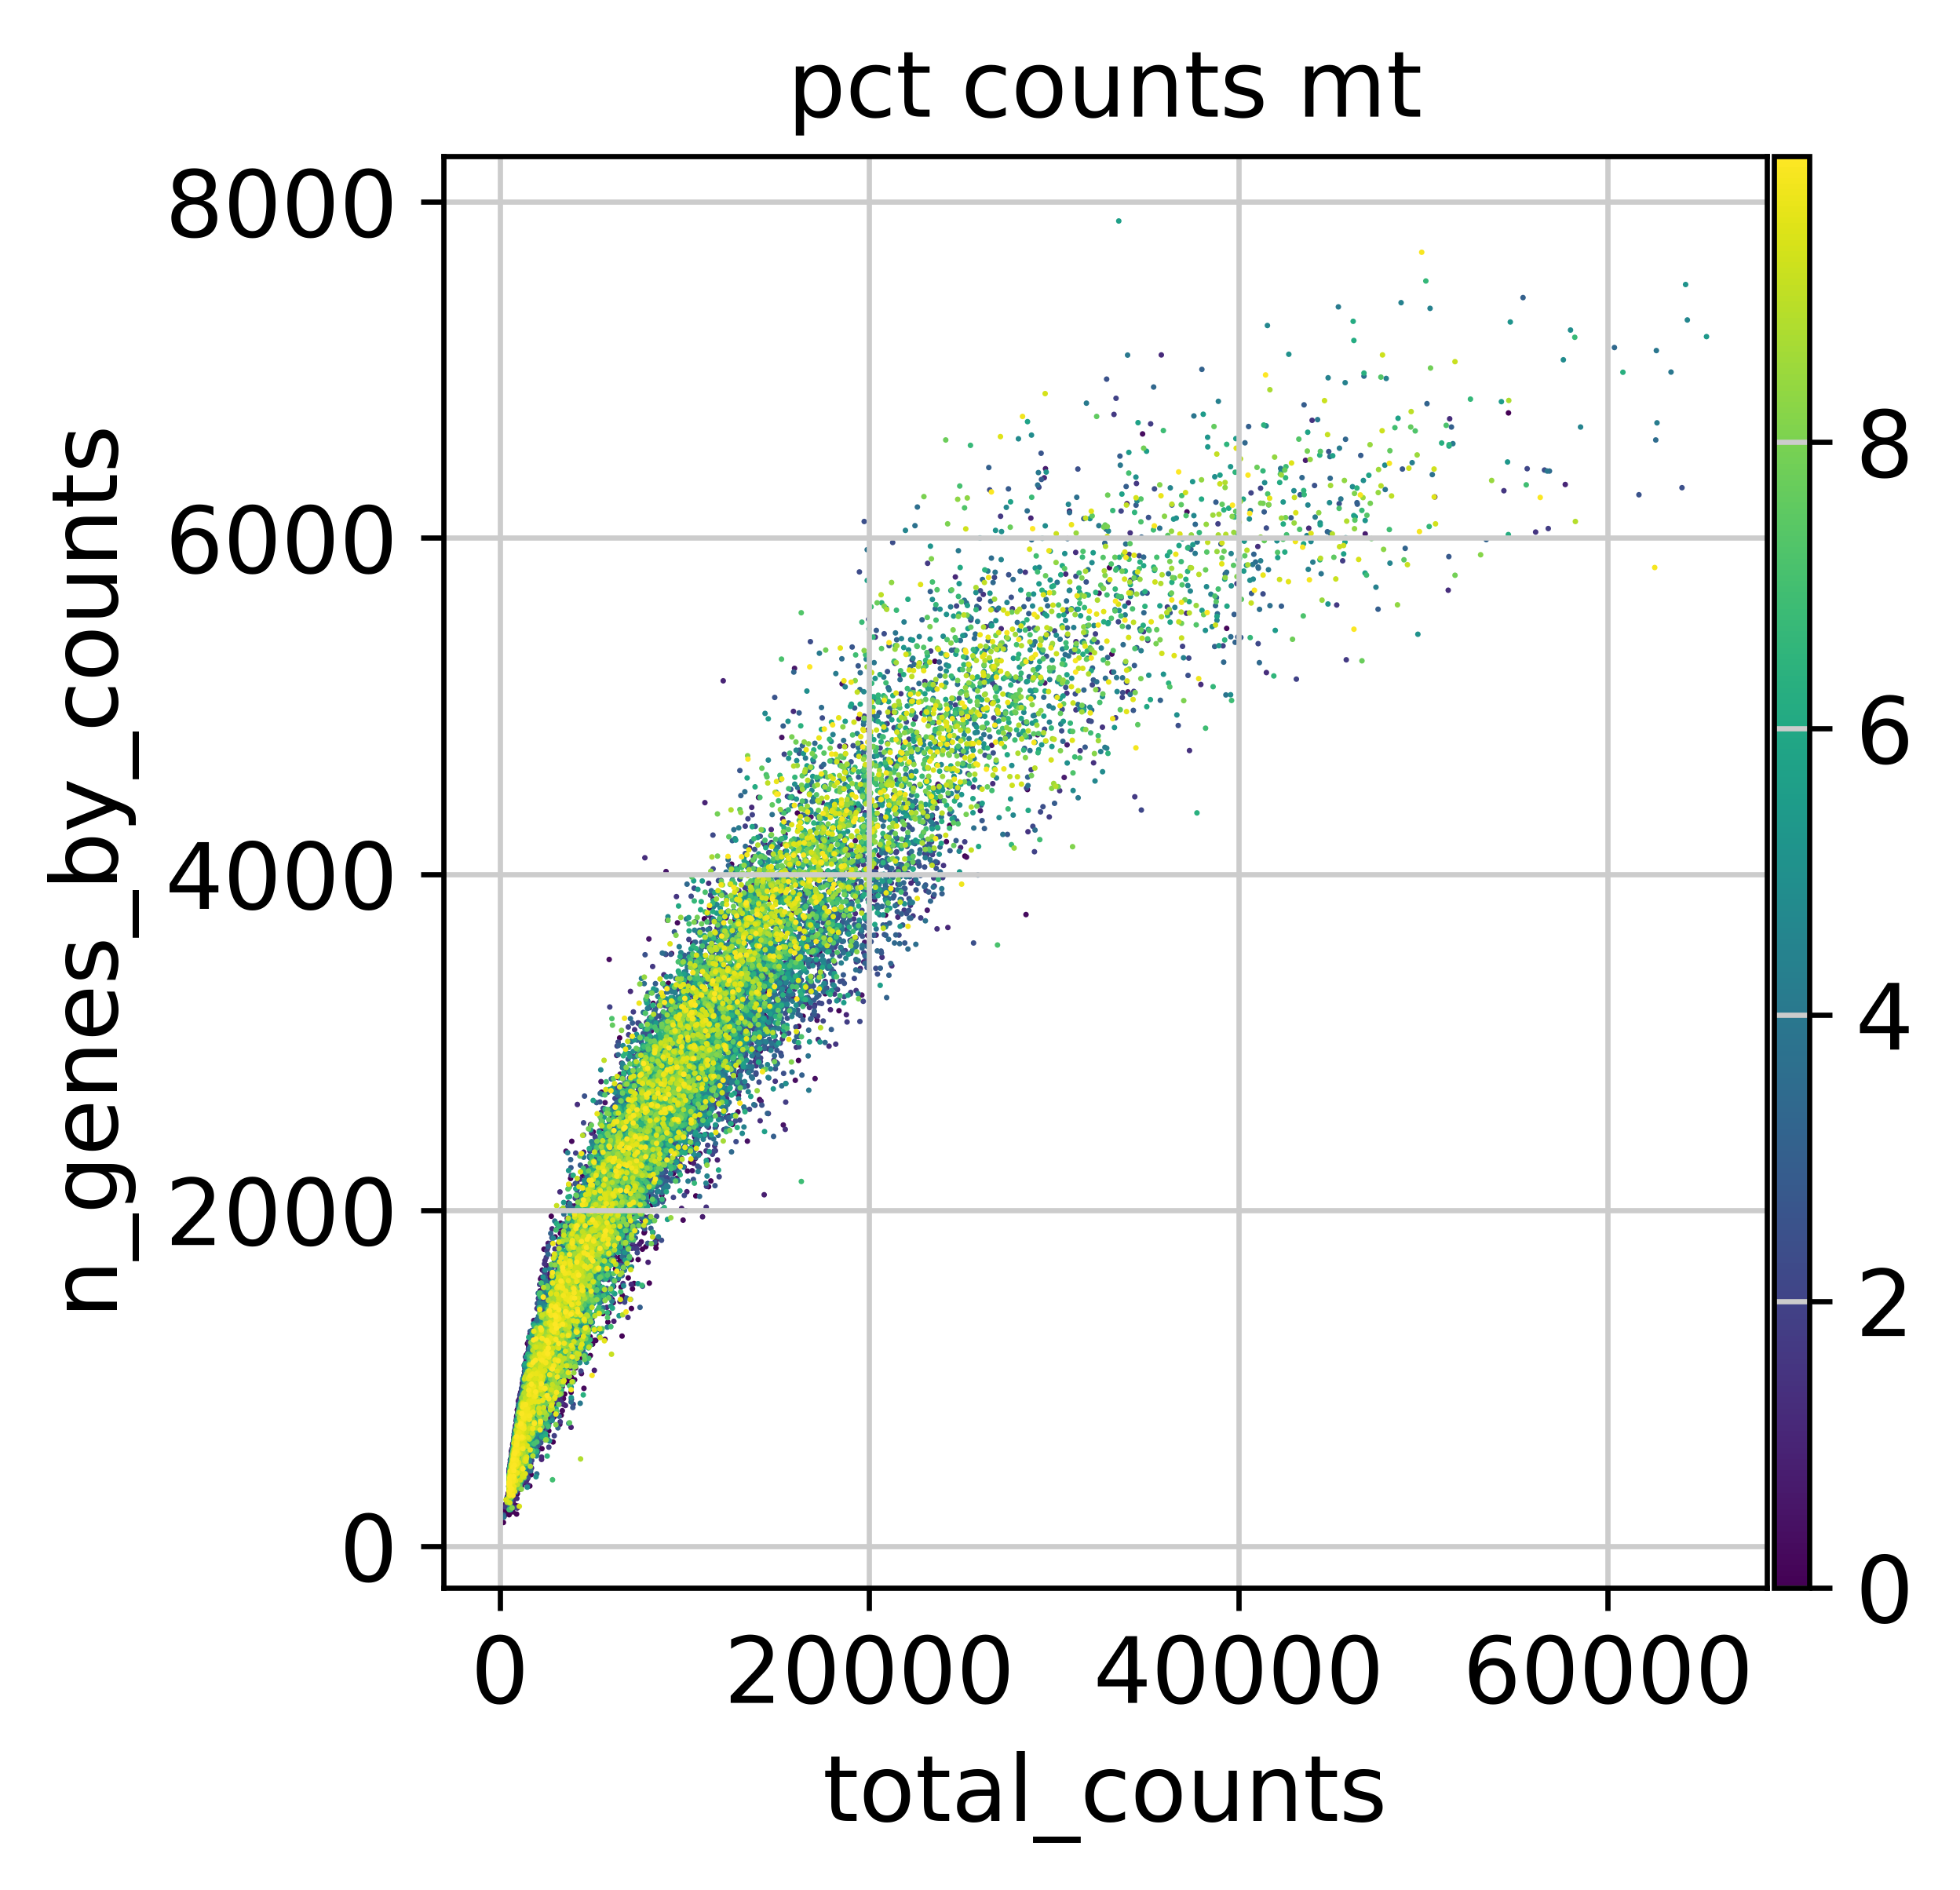

In [118]:
# The usual complexity scatter: counts vs genes, coloured by mitochondrial content.
sc.pl.scatter(
    sub,
    x='total_counts',
    y='n_genes_by_counts',
    color='pct_counts_mt',
    save=f'_{C.compartment()}_counts_vs_genes.png',
)

## Cell filter

Same criteria as 01_2 (pct_counts_mt \< 10, n_genes_by_counts \> 100).

In [119]:
n_before = sub.n_obs
fail_genes = (sub.obs['n_genes_by_counts'] <= C.MIN_GENES)
fail_mt = (sub.obs['pct_counts_mt'] >= C.MAX_PCT_MT)
print(f'n_genes_by_counts <= {C.MIN_GENES} : {int(fail_genes.sum()):,} cells')
print(f'pct_counts_mt     >= {C.MAX_PCT_MT} : {int(fail_mt.sum()):,} cells')
print(f'either                       : {int((fail_genes | fail_mt).sum()):,} cells')

sub = sub[~(fail_genes | fail_mt).to_numpy()].copy()
print(f'\nCells: {n_before:,} -> {sub.n_obs:,} ({100 * sub.n_obs / n_before:.1f}% retained)')

n_genes_by_counts <= 100 : 0 cells
pct_counts_mt     >= 10 : 0 cells
either                       : 0 cells

Cells: 42,291 -> 42,291 (100.0% retained)


## Gene filter

In [120]:
n_genes_before = sub.n_vars
detected = np.asarray((sub.X > 0).sum(axis=0)).ravel()
print(f'Total number of genes: {n_genes_before:,}')
print(f'  detected in 0 cells        : {int((detected == 0).sum()):,}')
print(f'  detected in < {C.MIN_CELLS} cells  : {int((detected < C.MIN_CELLS).sum()):,}')

sc.pp.filter_genes(sub, min_cells=C.MIN_CELLS)
print(f'Genes after the filter: {sub.n_vars:,} '
      f'({100 * sub.n_vars / n_genes_before:.1f}% retained)')

# QC columns are per-cell sums over the genes that are actually left.
sc.pp.calculate_qc_metrics(sub, qc_vars=['mt', 'ribo'], percent_top=None, log1p=True, inplace=True)

Total number of genes: 30,869
  detected in 0 cells        : 2,911
  detected in < 3 cells  : 5,612
filtered out 5612 genes that are detected in less than 3 cells
Genes after the filter: 25,257 (81.8% retained)


### QC figures (after the cell and gene filters)

wrote violin_tum_qc_after_cell_and_gene_filter_unintegrated_comparison.png


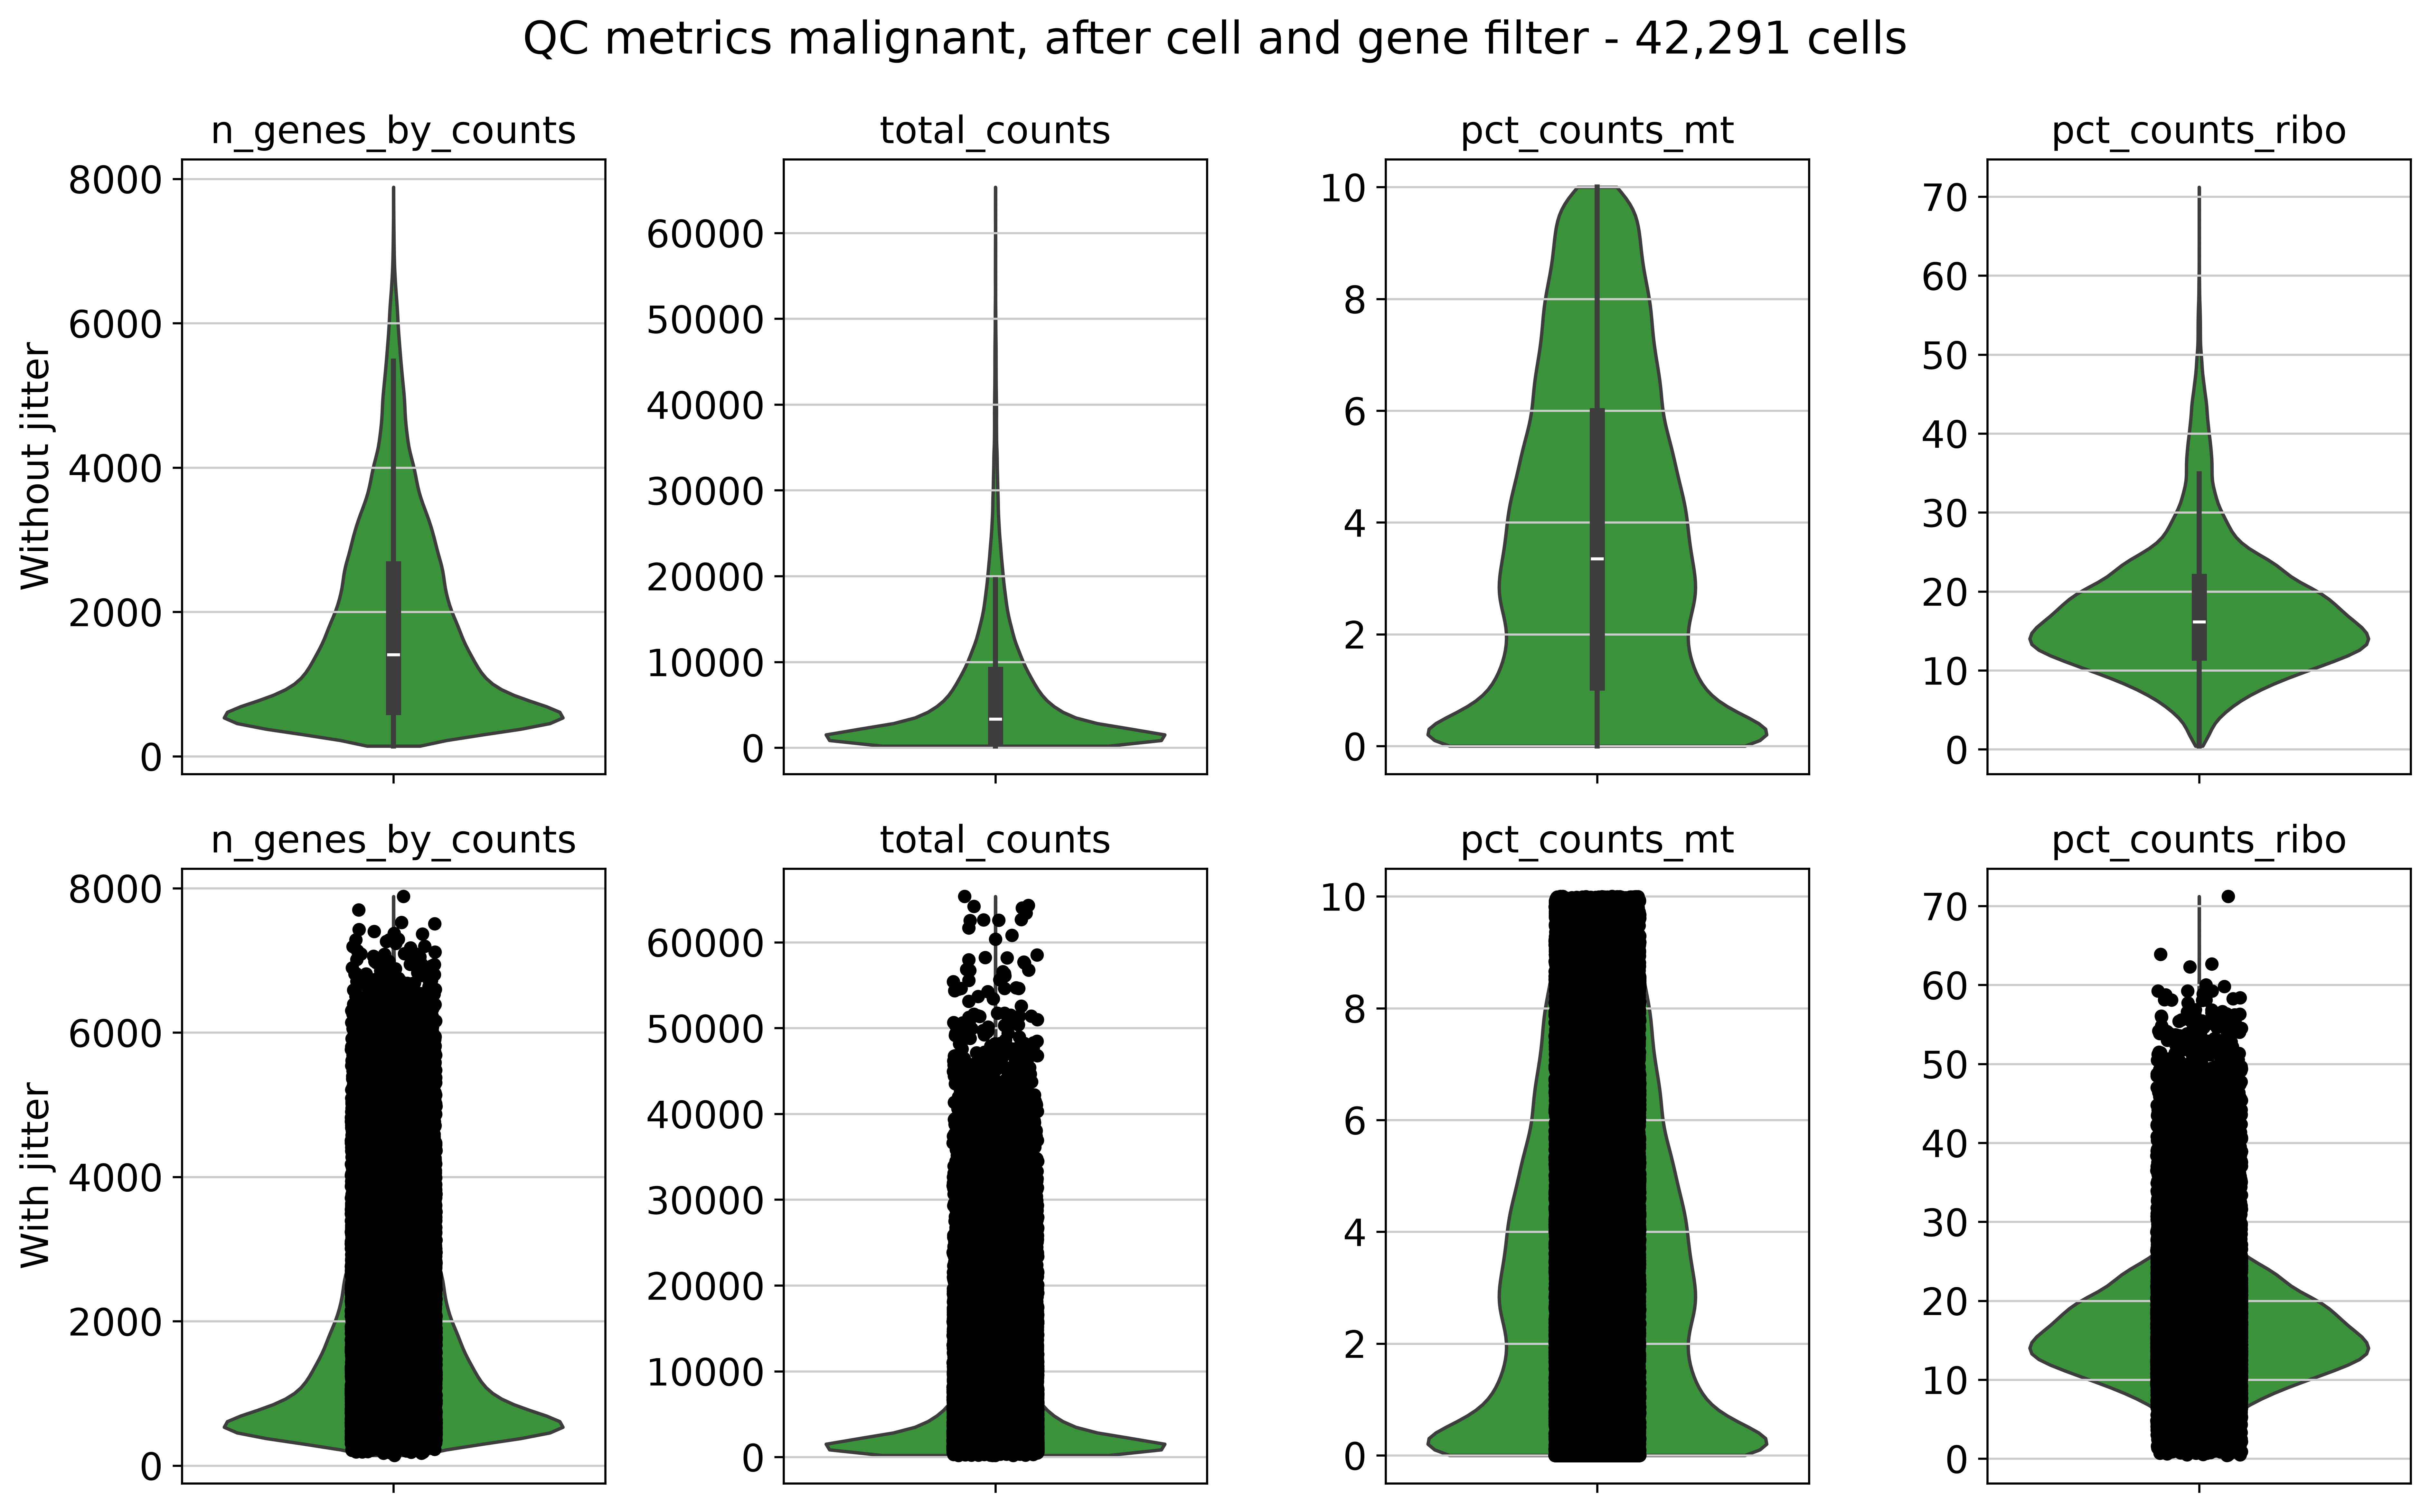

In [121]:
violin_qc(sub.obs, 'after_cell_and_gene_filter')

## Batch census

cohort is the batch key downstream: the HVGs are selected per patient and DRVI fits a dispersion per gene and per patient, both unreliable on a few hundred cells.

- Size (MIN_CELLS_PER_COHORT = 100): drops 4 cohorts (Patient05, 03, 30, 66), 348 cells in total.
- Completeness (DROP_INCOMPLETE_COHORTS): off. Requiring every timepoint would drop whole patients for one empty biopsy, e.g. Patient63 and its 2,297 malignant cells with no RTPD1.

Both are applied after the QC filters above.

In [122]:
cells_per_cohort = sub.obs[C.BATCH_KEY].value_counts()
cells_per_cohort = cells_per_cohort[cells_per_cohort > 0]
print(f'{cells_per_cohort.size} cohorts | '
      f'min {cells_per_cohort.min():,} ({cells_per_cohort.idxmin()}) | '
      f'median {int(cells_per_cohort.median()):,} | '
      f'max {cells_per_cohort.max():,} ({cells_per_cohort.idxmax()})')

small = cells_per_cohort[cells_per_cohort < C.MIN_CELLS_PER_COHORT]
if len(small):
    print(f'\n{len(small)} cohort(s) below {C.MIN_CELLS_PER_COHORT} cells:')
    print(small.to_string())
else:
    print(f'\nNo cohort below {C.MIN_CELLS_PER_COHORT} cells.')

cells_per_cohort.sort_values()

24 cohorts | min 78 (Patient66) | median 832 | max 7,684 (Patient16)

4 cohort(s) below 100 cells:
cohort
Patient05    94
Patient03    89
Patient30    87
Patient66    78


cohort
Patient66      78
Patient30      87
Patient03      89
Patient05      94
Patient10     199
Patient20     218
Patient42     278
Patient01     369
Patient64     455
Patient09     471
Patient48     472
Patient18     746
Patient19     919
Patient11    1116
Patient45    2106
Patient46    2218
Patient63    2297
Patient17    2386
Patient47    2701
Patient43    2826
Patient53    3659
Patient26    4826
Patient56    5997
Patient16    7684
Name: count, dtype: int64

In [123]:
# What the threshold actually costs.
rows = [{'threshold': t, 'cohorts': int((cells_per_cohort >= t).sum()),
         'cells': int(cells_per_cohort[cells_per_cohort >= t].sum())}
        for t in (50, 100, 150, 200, 300, 500)]
pd.DataFrame(rows).set_index('threshold')

,cohorts,cells
threshold,,
50,24,42291
100,20,41943
150,20,41943
200,19,41744
300,17,41248
500,13,39481


<BarContainer object of 24 artists>

Text(23.5, 114.99999999999999, 'MIN_CELLS_PER_COHORT = 100')

[Text(0, 0, 'Patient16'),
 Text(1, 0, 'Patient56'),
 Text(2, 0, 'Patient26'),
 Text(3, 0, 'Patient53'),
 Text(4, 0, 'Patient43'),
 Text(5, 0, 'Patient47'),
 Text(6, 0, 'Patient17'),
 Text(7, 0, 'Patient63'),
 Text(8, 0, 'Patient46'),
 Text(9, 0, 'Patient45'),
 Text(10, 0, 'Patient11'),
 Text(11, 0, 'Patient19'),
 Text(12, 0, 'Patient18'),
 Text(13, 0, 'Patient48'),
 Text(14, 0, 'Patient09'),
 Text(15, 0, 'Patient64'),
 Text(16, 0, 'Patient01'),
 Text(17, 0, 'Patient42'),
 Text(18, 0, 'Patient20'),
 Text(19, 0, 'Patient10'),
 Text(20, 0, 'Patient05'),
 Text(21, 0, 'Patient03'),
 Text(22, 0, 'Patient30'),
 Text(23, 0, 'Patient66')]

Text(0, 0.5, 'cells')

Text(0.5, 1.0, 'Cells per cohort (tum)')

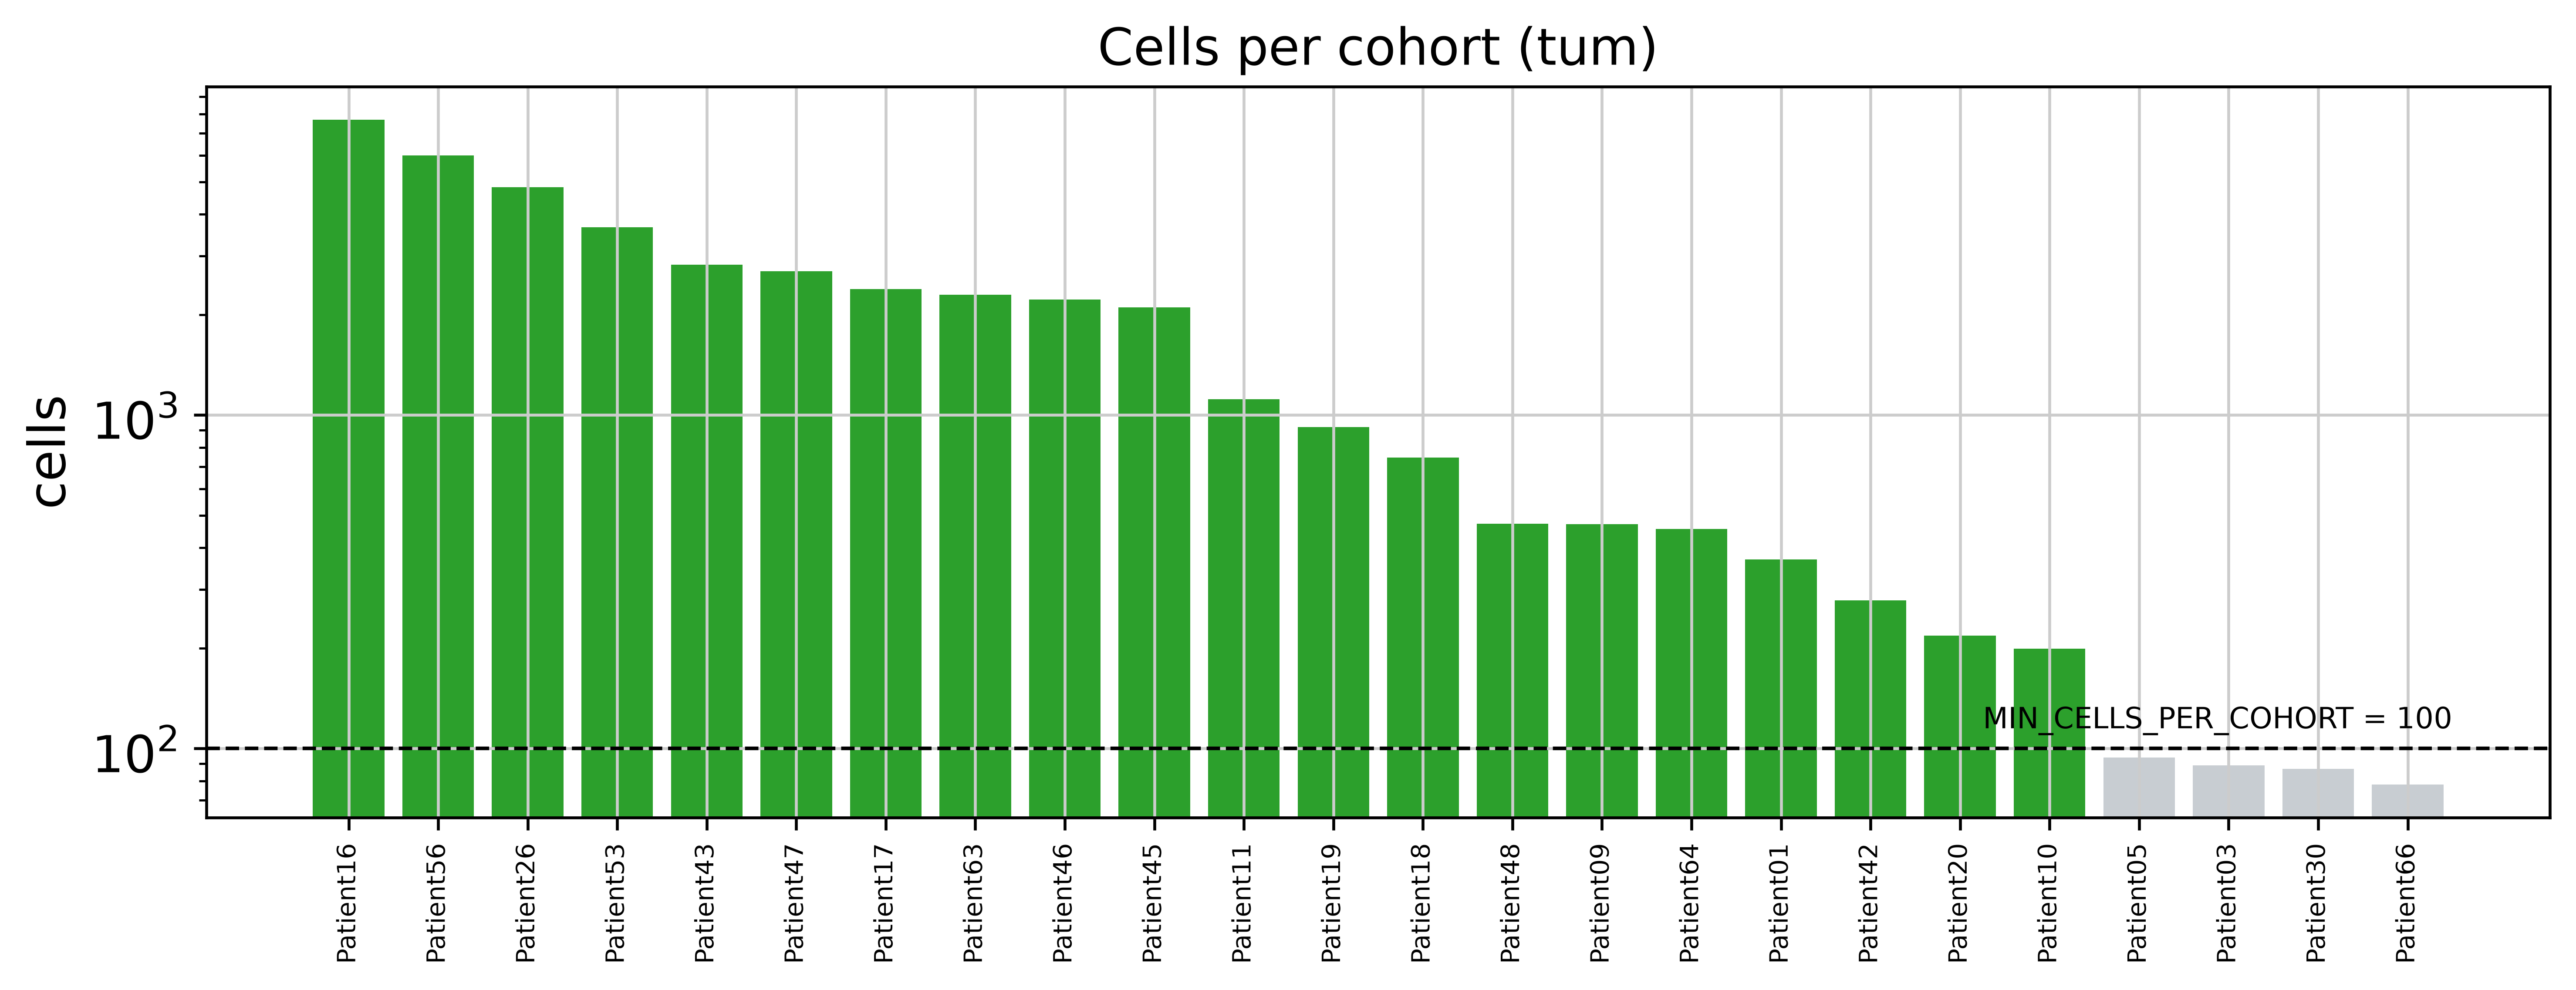

In [124]:
fig, ax = plt.subplots(figsize=(max(7, 0.42 * len(cells_per_cohort)), 4))
order = cells_per_cohort.sort_values(ascending=False)
kept = order >= C.MIN_CELLS_PER_COHORT
ax.bar(range(len(order)), order.to_numpy(),
       color=[QC_COLOR if k else '#C8CDD2' for k in kept])
ax.axhline(C.MIN_CELLS_PER_COHORT, color='black', ls='--', lw=1)
ax.text(len(order) - 0.5, C.MIN_CELLS_PER_COHORT * 1.15,
        f'MIN_CELLS_PER_COHORT = {C.MIN_CELLS_PER_COHORT}', ha='right', fontsize=8)
ax.set_yscale('log')
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order.index, rotation=90, fontsize=7)
ax.set_ylabel('cells')
ax.set_title(f'Cells per cohort ({C.compartment()})')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, f'cells_per_cohort_{C.compartment()}.png'), dpi=300,
            bbox_inches='tight')
plt.show()

In [125]:
cohort_x_treatment = pd.crosstab(
    sub.obs[C.BATCH_KEY], sub.obs[C.TREATMENT_KEY]
).reindex(columns=list(C.REQUIRED_TREATMENTS), fill_value=0)

incomplete = cohort_x_treatment.index[(cohort_x_treatment == 0).any(axis=1)]
if len(incomplete):
    print(f"{len(incomplete)} cohort(s) missing at least one of "
          f"{'/'.join(C.REQUIRED_TREATMENTS)} "
          f"({'DROPPED' if C.DROP_INCOMPLETE_COHORTS else 'kept: the filter is off'}):")
    for ch in incomplete:
        miss = [t for t in C.REQUIRED_TREATMENTS if cohort_x_treatment.loc[ch, t] == 0]
        print(f"  {ch}: no {'/'.join(miss)} ({int(cells_per_cohort[ch]):,} cells)")
else:
    print(f"Every cohort covers all of {'/'.join(C.REQUIRED_TREATMENTS)}.")

cohort_x_treatment

9 cohort(s) missing at least one of BASE/PD1/RTPD1 (kept: the filter is off):
  Patient01: no PD1 (369 cells)
  Patient03: no RTPD1 (89 cells)
  Patient05: no RTPD1 (94 cells)
  Patient10: no RTPD1 (199 cells)
  Patient30: no RTPD1 (87 cells)
  Patient42: no RTPD1 (278 cells)
  Patient48: no RTPD1 (472 cells)
  Patient63: no RTPD1 (2,297 cells)
  Patient66: no BASE/RTPD1 (78 cells)


treatment,BASE,PD1,RTPD1
cohort,,,
Patient01,253,0,116
Patient03,85,4,0
Patient05,62,32,0
Patient09,279,149,43
Patient10,63,136,0
Patient11,729,385,2
Patient16,583,7098,3
Patient17,170,218,1998
Patient18,164,570,12


In [126]:
to_drop = pd.Index([])
to_drop = to_drop.union(small.index)
if C.DROP_INCOMPLETE_COHORTS:
    to_drop = to_drop.union(incomplete)

if len(to_drop):
    print(f'Dropping {len(to_drop)} cohort(s):')
    for ch in to_drop:
        reasons = []
        if ch in small.index:
            reasons.append(f'< {C.MIN_CELLS_PER_COHORT} cells')
        if C.DROP_INCOMPLETE_COHORTS and ch in incomplete:
            reasons.append('no ' + '/'.join(t for t in C.REQUIRED_TREATMENTS
                                            if cohort_x_treatment.loc[ch, t] == 0))
        print(f"  {ch}: {'; '.join(reasons)} ({int(cells_per_cohort[ch]):,} cells)")

    n_before, n_cohorts_before = sub.n_obs, sub.obs[C.BATCH_KEY].nunique()
    sub = sub[~sub.obs[C.BATCH_KEY].isin(to_drop)].copy()

    # Every categorical can lose a level with a whole patient (sample, response, and the labels
    # only that patient carried), not just the batch key.
    for col in sub.obs.columns:
        if isinstance(sub.obs[col].dtype, pd.CategoricalDtype):
            sub.obs[col] = sub.obs[col].cat.remove_unused_categories()

    print(f'\nCells   : {n_before:,} -> {sub.n_obs:,} ({100 * sub.n_obs / n_before:.1f}% retained)')
    print(f'Cohorts : {n_cohorts_before} -> {sub.obs[C.BATCH_KEY].nunique()}')

    # Genes can fall below the threshold once a whole patient is gone; zero-count ones would
    # break scran, so this refilter is not optional.
    n_genes_before = sub.n_vars
    sc.pp.filter_genes(sub, min_cells=C.MIN_CELLS)
    print(f'Genes   : {n_genes_before:,} -> {sub.n_vars:,}')

    sc.pp.calculate_qc_metrics(sub, qc_vars=['mt', 'ribo'], percent_top=None, log1p=True,
                               inplace=True)
else:
    print('No cohort dropped.')

Dropping 4 cohort(s):
  Patient05: < 100 cells (94 cells)
  Patient03: < 100 cells (89 cells)
  Patient30: < 100 cells (87 cells)
  Patient66: < 100 cells (78 cells)

Cells   : 42,291 -> 41,943 (99.2% retained)
Cohorts : 24 -> 20
filtered out 60 genes that are detected in less than 3 cells
Genes   : 25,257 -> 25,197


### QC figures (after the cohort drops)

The last round: the cells of the dropped cohorts are gone, the gene filter has run a second time
and the QC columns have been recomputed over the genes that are actually left. These are the
distributions of the object that gets written.

wrote violin_tum_qc_after_cohort_drop_unintegrated_comparison.png


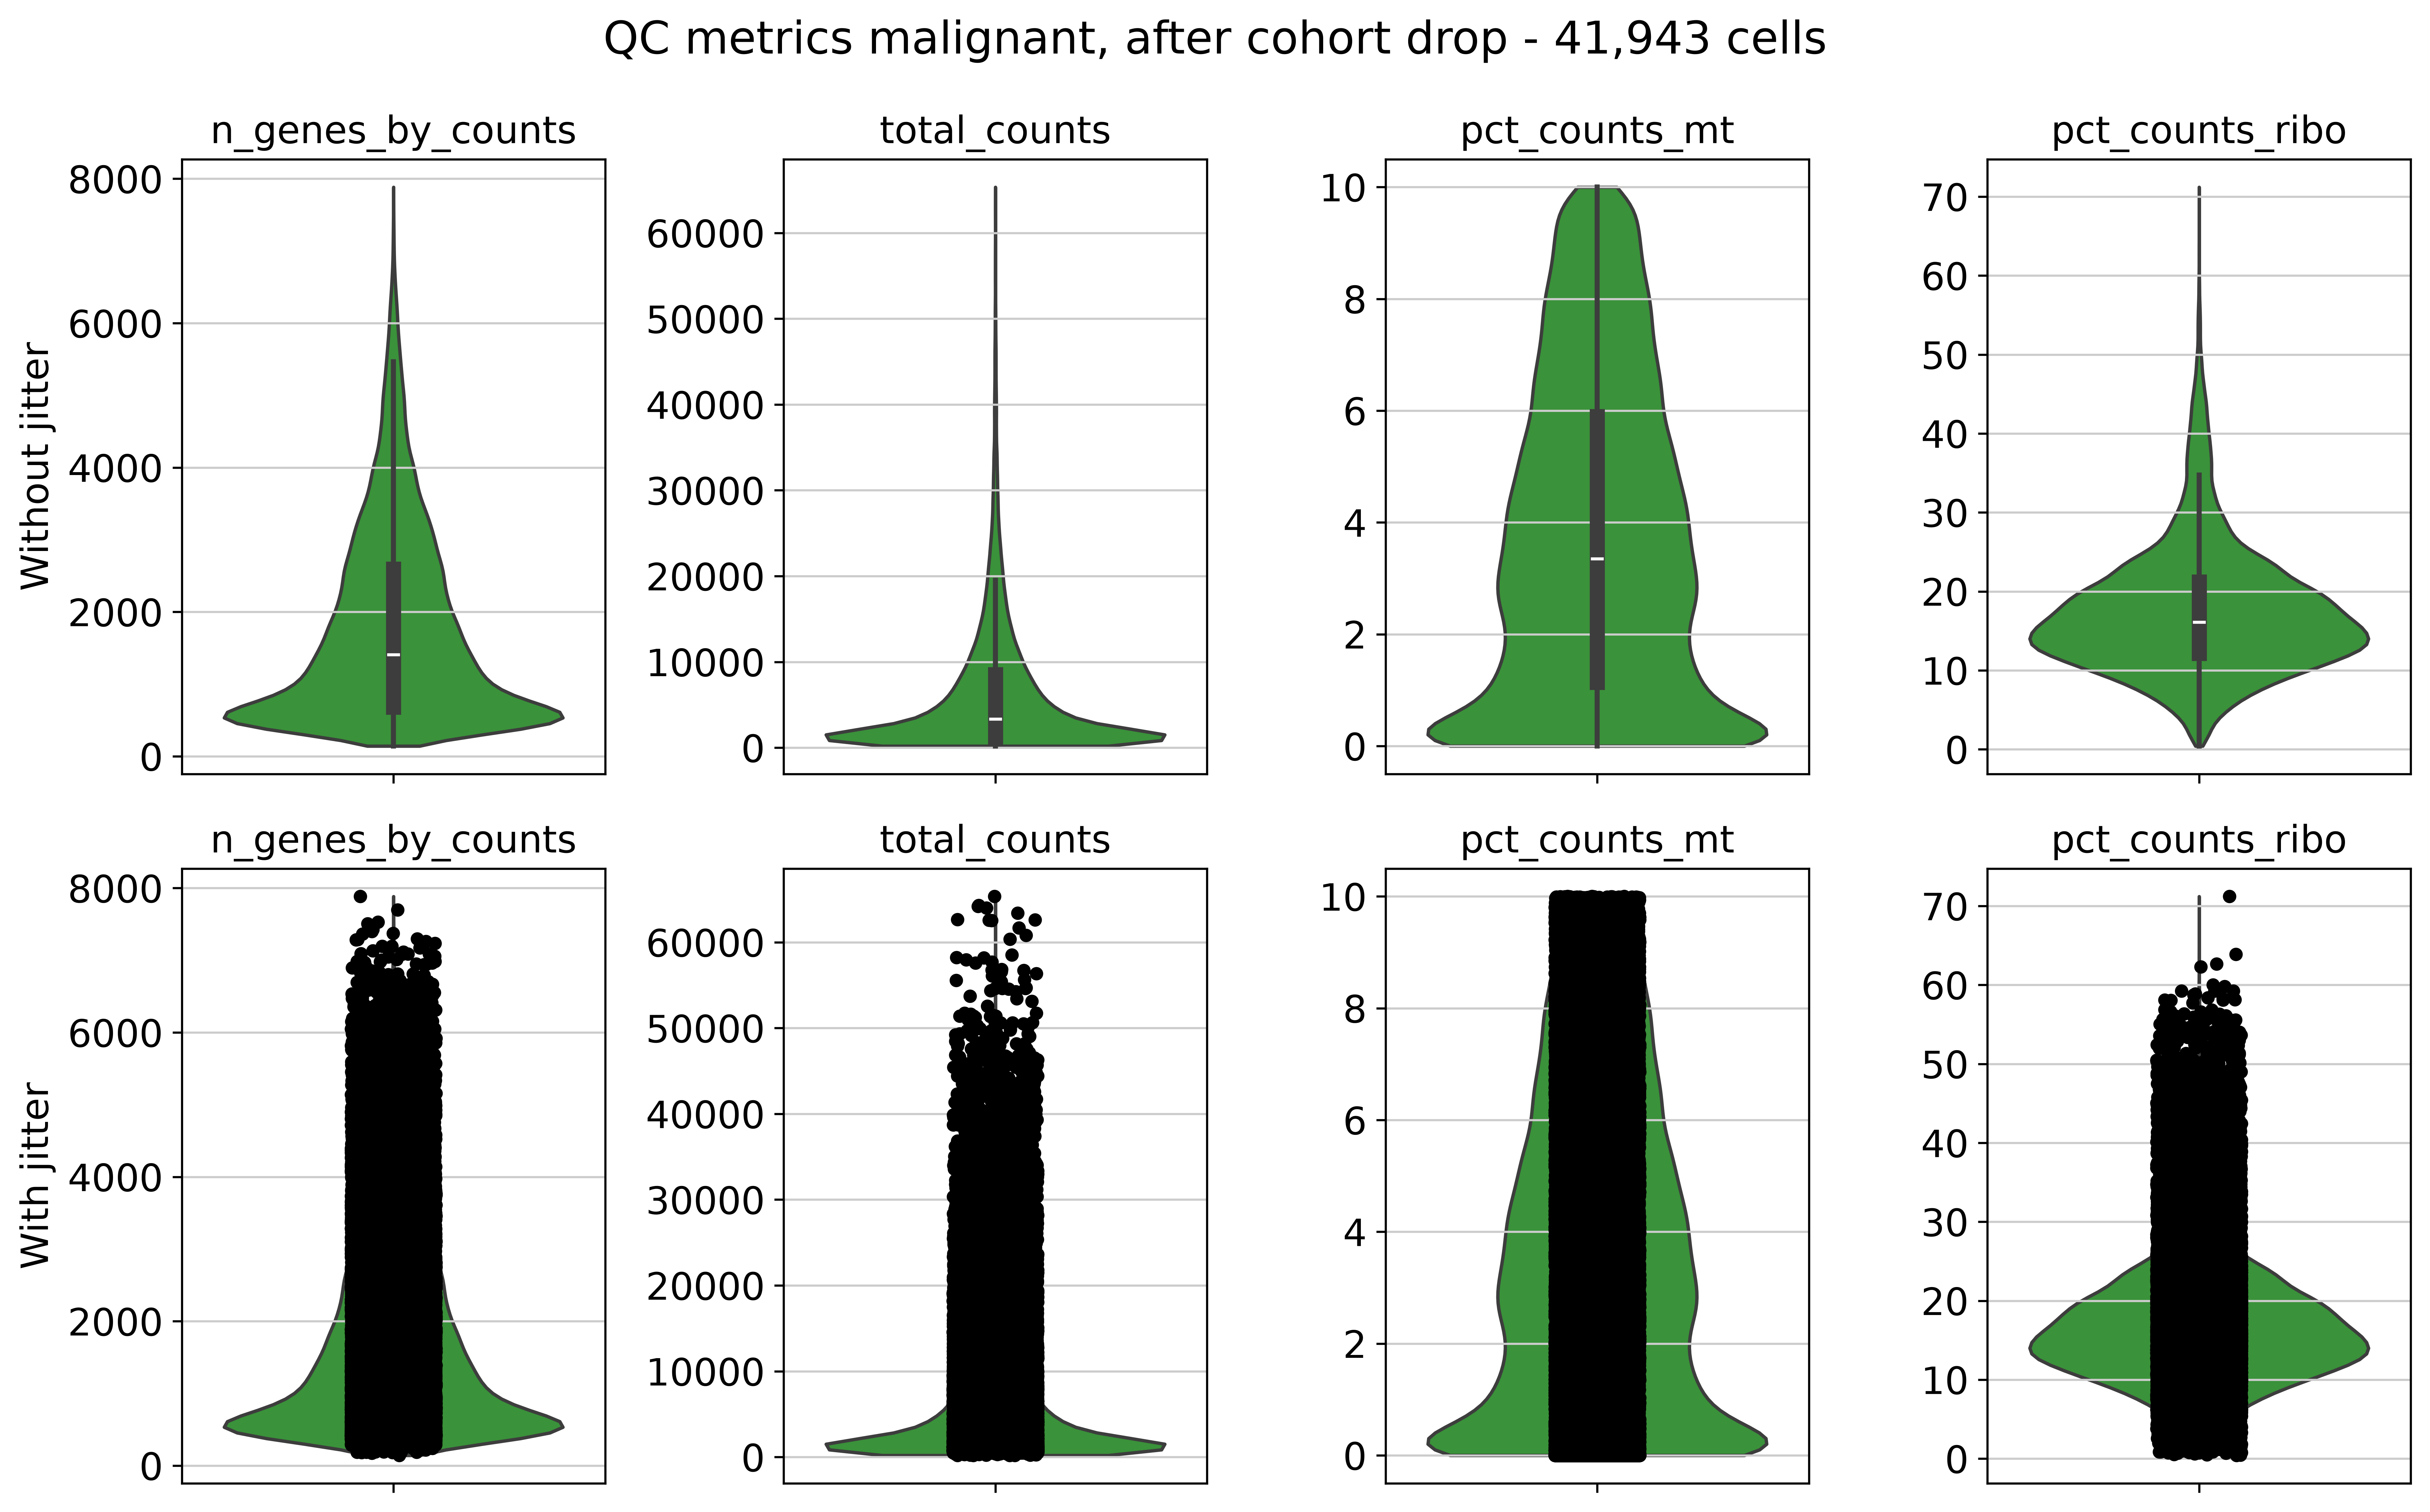

In [127]:
if len(to_drop):
    violin_qc(sub.obs, 'after_cohort_drop')
else:
    print('no cohort dropped: the round above is already the final one')

## Post-conditions, then write

In [128]:
# Checked before writing rather than discovered by scran an hour later.
counts_values = sub.layers['counts'].data
x_values = sub.X.data
assert np.allclose(x_values, np.round(x_values)), '.X must hold raw integer counts'
assert np.array_equal(x_values, counts_values), ".X and layers['counts'] must be identical here"
assert int(np.asarray(sub.X.sum(axis=0) == 0).sum()) == 0, 'zero-count genes left; scran would fail'
assert 'size_factors' not in sub.obs, 'the phase-01 size factors are still here'
assert not sub.obsm and not sub.varm and not sub.obsp, 'a derived slot survived'

assert sub.obs[C.COMPARTMENT_KEY].nunique() == 1, 'the compartment column is not constant'
assert sub.obs['fraction'].nunique() == 1, 'the subset spans both fractions'
assert sub.obs[C.BATCH_KEY].value_counts().min() >= C.MIN_CELLS_PER_COHORT, \
    f'a cohort under {C.MIN_CELLS_PER_COHORT} cells survived'
assert (sub.obs[C.STATUS_KEY] != 'not_tested').all(), 'an untested cell survived the subset'

assert (sub.obs[C.STATUS_KEY] == 'malignant').all(), 'a non-malignant cell survived'
assert sub.obs[C.LABEL_KEY].nunique() == 1, \
    'cell_type should be the constant malignant label on this subset'
# The pre-CNV label is the only label that still varies on this subset.
assert sub.obs[C.PRIOR_LABEL_KEY].nunique() > 1, 'the pre-CNV label is constant too'

if C.DROP_INCOMPLETE_COHORTS:
    final_table = pd.crosstab(sub.obs[C.BATCH_KEY], sub.obs[C.TREATMENT_KEY]).reindex(
        columns=list(C.REQUIRED_TREATMENTS), fill_value=0)
    assert not (final_table == 0).any().any(), 'cohorts still missing a timepoint'

print('All post-conditions passed.')
print(f'{C.LABEL_KEY}: {sub.obs[C.LABEL_KEY].nunique()} level(s) | '
      f'{C.PRIOR_LABEL_KEY}: {sub.obs[C.PRIOR_LABEL_KEY].nunique()} level(s)')

All post-conditions passed.
cell_type: 1 level(s) | cell_type_01_4: 10 level(s)


## Saving dataset

shiao.h5ad was written with pandas 3, so its string indices and columns are pandas StringArrays, which readers older than anndata 0.11 cannot open (and some environments of this project are pinned older). 02_integration_benchmark/utils/h5ad_compat.py converts them to plain object arrays and checks the file it wrote. It is applied once, here, because every later step starts from this file.

In [129]:
sys.path.insert(0, os.path.join(REPO_ROOT, '02_integration_benchmark', 'utils'))
from h5ad_compat import write_h5ad_compat

write_h5ad_compat(sub, OUTPUT_H5AD, compression='gzip')
print(f'Wrote {OUTPUT_H5AD} '
      f'({sub.n_obs:,} cells x {sub.n_vars:,} genes, '
      f'{os.path.getsize(OUTPUT_H5AD) / 1024 ** 3:.2f} GB on disk)')
sub

[h5ad_compat] 4 dtype adjustments before writing:
    obs.index -> object
    obs['predicted_doublet'] boolean -> numpy
    var.index -> object
    var['gene_ids'] string -> object
[h5ad_compat] wrote /home/catt/QCB-thesis-final/datasets/03_tum/shiao_tum_raw.h5ad, readable by anndata >=0.7


['obs.index -> object',
 "obs['predicted_doublet'] boolean -> numpy",
 'var.index -> object',
 "var['gene_ids'] string -> object"]

Wrote /home/catt/QCB-thesis-final/datasets/03_tum/shiao_tum_raw.h5ad (41,943 cells x 25,197 genes, 0.33 GB on disk)


AnnData object with n_obs × n_vars = 41943 × 25197
    obs: 'sample', 'batch', 'cohort', 'treatment', 'fraction', 'dataset_origin', 'response', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'is_doublet_shiao', 'high_umi_doublet', 'cell_type', 'celltypist_predicted', 'cnv_status', 'cnv_score', 'cnv_corr', 'cell_type_01_4', 'celltypist_predicted_cnv', 'compartment'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: 'counts', None (.X)

## Next

subsetting_all.sh turns shiao_tum_raw.h5ad into the definitive object shiao_tum.h5ad and the DRVI input shiao_tum_hvg_2k_nomt.h5ad; visualization_tum.ipynb inspects the result.